# Onze Prime · training the record hunter

How the bot learns to chase the Três Grandes record (**995 points = 90.45, shown as "90,5"**), step by step:

| Step | What | Why |
|---|---|---|
| 1 | Frame the target | What a 995 XI needs: which players, which slots |
| 2 | Build the environment | A Python copy of the site's engine, checked against the real JS |
| 3 | Pick a metric | The record is rare (~1 in 4,000), so measure *survival* instead |
| 4 | Define the policy family | One decision rule with tunable knobs |
| 5 | Train | Search the knobs on the same training seeds for every config |
| 6 | Validate | Re-test the best configs on fresh seeds, with confidence intervals |
| 7 | Prove it | Find a record game offline and replay it |
| 8 | Plan the time | Seconds per simulation and per live attempt, hours to the record |
| 9 | Play live | Autopilot hunt, or copilot while you play |
| 10 | Can we go higher? | Ceiling under every rule set and mode |
| 4b / 11 | Decision anatomy & bias | Where a bias can act, and a fair test of it |

The full run takes about 12 minutes on 8 cores.

In [1]:
import sys, time, glob, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from onzeprime import data, engine, optimizer as opt, strategies as st, simulate as sim, training as tr

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
clubs, by_club = data.load()
pool = opt.pool_for_mode(by_club, "grandes")
WORKERS = 7
TRAIN_SEEDS = range(1_000_000, 1_025_000)     # 25k seeds, shared by every config
VALID_START = 5_000_000                       # held-out seeds, never seen in training

## Step 1 · Frame the target

The record is a **perfect XI**. For every slot we list who can be in it in *some* team that sums to 995
(exact check: put the player there, solve the best completion of the other 10 slots, see if it still reaches 995).
Slots with a single name are **must-haves**: if that player never shows up, the game is lost.

In [2]:
names = {p.id: p.nome for p in pool}
rows = []
for f in ["3-5-2", "4-4-2", "4-2-4"]:
    for slot, ids in opt.optimal_candidates(pool, f).items():
        rows.append({"formation": f, "slot": slot, "n_alive": len(ids), "candidates": ", ".join(sorted(names[i] for i in ids))})
alive_map = pd.DataFrame(rows)
alive_map.pivot_table(index="formation", values="n_alive", aggfunc=lambda s: (s == 1).sum()).rename(columns={"n_alive": "must-have slots"})

,must-have slots
formation,
3-5-2,3
4-2-4,3
4-4-2,3


In [3]:
alive_map[alive_map.formation == "3-5-2"]

,formation,slot,n_alive,candidates
0,3-5-2,PL1,2,"Gyökeres, Mário Jardel"
1,3-5-2,PL2,2,"Gyökeres, Mário Jardel"
2,3-5-2,AE,1,Luis Díaz
3,3-5-2,MC1,2,"Bruno Fernandes, Deco"
4,3-5-2,MC2,2,"Bruno Fernandes, Deco"
5,3-5-2,AD,1,Hulk
6,3-5-2,MDC,1,Matić
7,3-5-2,DC1,7,"Bruno Alves, Coates, David Luiz, Garay, Luisão..."
8,3-5-2,DC2,7,"Bruno Alves, Coates, David Luiz, Garay, Luisão..."
9,3-5-2,DC3,7,"Bruno Alves, Coates, David Luiz, Garay, Luisão..."


## Step 2 · The environment (simulator)

`engine.Game` is a line-by-line port of the site's `core.js`: same `mulberry32` RNG, weighted 6-option sampling,
club draw, swaps and position rules. The parity tests run the **real site code** in headless Chromium and require identical
draws for many seeds. Once that holds, every offline game is an exact sample of a real one.

In [4]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", str(ROOT / "tests")], capture_output=True, text=True, cwd=ROOT)
print(r.stdout.strip().splitlines()[-1]); assert r.returncode == 0

36 passed in 3.13s


In [5]:
# Cost of one simulation (single core)
hunter = st.RecordHunterPolicy(pool, "3-5-2")
def bench(n, early_abort):
    t = time.perf_counter()
    for s in range(n):
        tr.play_tracked(clubs, by_club, hunter, "3-5-2", 9_000_000 + s, early_abort=early_abort)
    return (time.perf_counter() - t) / n * 1000
ms_full, ms_abort = bench(400, False), bench(400, True)
print(f"full game: {ms_full:.1f} ms · stop when 995 is lost: {ms_abort:.1f} ms  (single core)")

full game: 8.2 ms · stop when 995 is lost: 3.8 ms  (single core)


## Step 3 · The metric: survival instead of wins

With p(record) ≈ 1/4,000, a 25k-game run sees only ~6 records, which is too noisy to rank configs.
So we track the whole path. After each pick, can the game still reach 995?

* **S(k)** = share of games still alive after *k* picks. P(record) = S(11).
* **h(k)** = hazard, the chance the *k*-th pick kills the game (given it was alive).

S(9) is seen ~10× more often than S(11) and moves with it, so it's the training signal. Training games
also **stop at the first death**, since a dead game can never become a record. That's the speed-up measured above.

,0,1,2,3,4,5,6,7,8,9,10,11
S(k),1.0,0.8126,0.5589,0.3402,0.1825,0.0897,0.0399,0.0157,0.0054,0.0012,0.0004,0.0001
h(k),NaN,0.1874,0.3122,0.3913,0.4637,0.5083,0.5551,0.6062,0.6590,0.7687,0.7097,0.6667


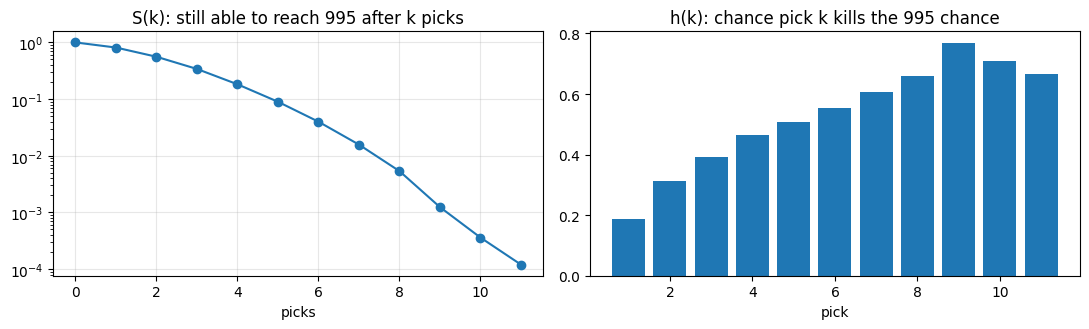

In [6]:
base = tr.evaluate("3-5-2", "ceiling", {"target_sum": 995}, TRAIN_SEEDS, WORKERS)
surv, haz = tr.survival(base), tr.hazard(base)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].semilogy(surv.index, surv.values, marker="o"); ax[0].set_title("S(k): still able to reach 995 after k picks")
ax[0].set_xlabel("picks"); ax[0].grid(alpha=.3)
ax[1].bar(haz.index, haz.values); ax[1].set_title("h(k): chance pick k kills the 995 chance"); ax[1].set_xlabel("pick")
plt.tight_layout()
pd.DataFrame({"S(k)": surv, "h(k)": haz}).T.round(4)

**Reading it:** most games die on the first picks. The first club offers none of the needed stars, and with only 2 swaps
there's no way to wait for them. Once a game survives about 6 picks, each extra pick is much safer. This is a game of
*draw luck*, and the policy can only (a) never throw away an alive game and (b) spend swaps at the right moment.

## Step 4 · The policy family (`RecordHunterPolicy`)

At each draw:

1. For every option × slot, compute the **ceiling** = points so far + rating + best completion (exact assignment).
2. **Alive picks** (ceiling still ≥ 995) are ranked by a score with three knobs:
   * `w_scarce`: prefer the slot with the fewest remaining alive candidates (lock the irreplaceable stars).
   * `w_close`: prefer picks that close a role entirely. The site draws one option per *open role*, so fewer open roles
     means more slots for weighted star draws.
   * `w_ovr`: small tie-break on rating.
3. No alive pick, but the game is still alive → **swap (rescue)**, but only from round `rescue_from_round` on
   (should early swaps be saved for later?).
4. Dead → the live bot restarts. In training, the game simply stops.

The formation is a knob too (only 3-5-2, 4-4-2 and 4-2-4 can reach 995).

## Step 4b · Anatomy of one decision (where a bias can act)

```
 draw: club + 6 options
        │
        ▼
 ① expand → one row per (option × role it can still play)
        │
        ▼
 ② ceiling_after = points so far + rating + best completion of the other free slots   (exact assignment)
        │            alive  ⇔  ceiling_after ≥ 995
        ▼
 ③ any alive row? ──yes──► score = w_scarce/alive_left + w_close·closes_role + w_ovr·ovr/100
        │                          + slot_bias[role] + player_bias[name] + club_bias[club]   ◄── YOUR BIAS
        │                          │
        │                          ├─ best score < proactive_swap_below (early rounds)? ──► SWAP (proactive)  ◄── BIAS
        │                          └─ otherwise ──► PICK the best-scored alive row
        no
        ▼
 ④ game still alive & swap left & round ≥ rescue_from_round ──► SWAP (rescue)                ◄── BIAS (timing)
        │ otherwise
        ▼
 ⑤ dead → pick best ceiling (live bot: restart now)
```

The cell below replays one game and prints this table at each decision. **chosen** marks the row taken, and the
`c_*` columns are the score components.

In [7]:
from IPython.display import display, Markdown
demo = st.RecordHunterPolicy(pool, "3-5-2")
g = engine.Game(clubs, by_club, "grandes", "3-5-2", seed=hit_seed_demo if "hit_seed_demo" in dir() else 5067439)
cols = ["player", "club", "ovr", "role", "slot", "ceiling_after", "alive", "alive_left", "c_scarce", "c_close", "c_ovr", "c_bias", "score"]
for step in range(5):
    if g.finished: break
    rows, d, why = demo.explain(g)
    t = pd.DataFrame(rows).reindex(columns=cols)
    t["chosen"] = [(d.kind == "pick" and r["_p"] is d.player and r["slot"] == d.slot_id) if "_p" in r else False for r in rows]
    display(Markdown(f"**Decision {step + 1}** · round {g.round()} · club **{g.draw.club.upper()}** · swaps left {g.swaps} · "
                     f"ceiling now {demo.ceiling_now(g):.0f} → **{d.kind.upper()}** ({why})"))
    display(t.round(3))
    g.swap() if d.kind == "swap" else g.choose(d.player, d.slot_id)

**Decision 1** · round 1 · club **SLB** · swaps left 2 · ceiling now 995 → **SWAP** (rescue swap: no option keeps 995 reachable)

,player,club,ovr,role,slot,ceiling_after,alive,alive_left,c_scarce,c_close,c_ovr,c_bias,score,chosen
0,Simão,slb,89,AE,AE,994.0,False,NaN,NaN,NaN,NaN,NaN,None,False
1,Simão,slb,89,AD,AD,992.0,False,NaN,NaN,NaN,NaN,NaN,None,False
2,Gaitán,slb,88,AE,AE,993.0,False,NaN,NaN,NaN,NaN,NaN,None,False
3,Gaitán,slb,88,MC,MC1,991.0,False,NaN,NaN,NaN,NaN,NaN,None,False
4,Gaitán,slb,88,AD,AD,991.0,False,NaN,NaN,NaN,NaN,NaN,None,False
5,Fejsa,slb,84,MDC,MDC,991.0,False,NaN,NaN,NaN,NaN,NaN,None,False
6,Nuno Gomes,slb,84,PL,PL1,985.0,False,NaN,NaN,NaN,NaN,NaN,None,False
7,Miguel,slb,83,AD,AD,986.0,False,NaN,NaN,NaN,NaN,NaN,None,False
8,Katsouranis,slb,82,MC,MC1,985.0,False,NaN,NaN,NaN,NaN,NaN,None,False
9,Katsouranis,slb,82,MDC,MDC,989.0,False,NaN,NaN,NaN,NaN,NaN,None,False


**Decision 2** · round 1 · club **FCP** · swaps left 1 · ceiling now 995 → **PICK** (best alive score)

,player,club,ovr,role,slot,ceiling_after,alive,alive_left,c_scarce,c_close,c_ovr,c_bias,score,chosen
0,Diogo Costa,fcp,88,GR,GR,995.0,True,2.0,0.5,0.0,0.088,0.0,0.588,True
1,Éder Militão,fcp,86,AD,AD,989.0,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,Éder Militão,fcp,86,DC,DC1,994.0,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,Fernando,fcp,86,MDC,MDC,993.0,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,Evanilson,fcp,84,PL,PL1,985.0,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5,Pepê,fcp,82,AE,AE,987.0,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6,Pepê,fcp,82,AD,AD,985.0,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7,Maicon,fcp,81,DC,DC1,989.0,False,NaN,NaN,NaN,NaN,NaN,NaN,False


**Decision 3** · round 2 · club **SLB** · swaps left 1 · ceiling now 995 → **SWAP** (rescue swap: no option keeps 995 reachable)

,player,club,ovr,role,slot,ceiling_after,alive,alive_left,c_scarce,c_close,c_ovr,c_bias,score,chosen
0,Gonçalo Ramos,slb,86,PL,PL1,987.0,False,NaN,NaN,NaN,NaN,NaN,None,False
1,Maxi Pereira,slb,85,AD,AD,988.0,False,NaN,NaN,NaN,NaN,NaN,None,False
2,Lindelöf,slb,84,DC,DC1,992.0,False,NaN,NaN,NaN,NaN,NaN,None,False
3,Siqueira,slb,82,AE,AE,987.0,False,NaN,NaN,NaN,NaN,NaN,None,False
4,Zahovič,slb,82,MC,MC1,985.0,False,NaN,NaN,NaN,NaN,NaN,None,False
5,André Almeida,slb,80,AD,AD,983.0,False,NaN,NaN,NaN,NaN,NaN,None,False
6,André Almeida,slb,80,MDC,MDC,987.0,False,NaN,NaN,NaN,NaN,NaN,None,False


**Decision 4** · round 2 · club **SCP** · swaps left 0 · ceiling now 995 → **PICK** (no swaps left: 995 lost on this pick)

,player,club,ovr,role,slot,ceiling_after,alive,alive_left,c_scarce,c_close,c_ovr,c_bias,score,chosen
0,Pedro Gonçalves,scp,88,AE,AE,993.0,False,NaN,NaN,NaN,NaN,NaN,None,True
1,Pedro Gonçalves,scp,88,MC,MC1,991.0,False,NaN,NaN,NaN,NaN,NaN,None,False
2,Pedro Gonçalves,scp,88,AD,AD,991.0,False,NaN,NaN,NaN,NaN,NaN,None,False
3,Gonçalo Inácio,scp,85,AE,AE,990.0,False,NaN,NaN,NaN,NaN,NaN,None,False
4,Gonçalo Inácio,scp,85,DC,DC1,993.0,False,NaN,NaN,NaN,NaN,NaN,None,False
5,Debast,scp,81,MDC,MDC,988.0,False,NaN,NaN,NaN,NaN,NaN,None,False
6,Debast,scp,81,DC,DC1,989.0,False,NaN,NaN,NaN,NaN,NaN,None,False
7,Teo Gutiérrez,scp,81,PL,PL1,982.0,False,NaN,NaN,NaN,NaN,NaN,None,False
8,Quaresma,scp,80,AE,AE,985.0,False,NaN,NaN,NaN,NaN,NaN,None,False
9,Quaresma,scp,80,AD,AD,983.0,False,NaN,NaN,NaN,NaN,NaN,None,False


**Decision 5** · round 3 · club **FCP** · swaps left 0 · ceiling now 993 → **PICK** (dead game: best remaining ceiling)

,player,club,ovr,role,slot,ceiling_after,alive,alive_left,c_scarce,c_close,c_ovr,c_bias,score,chosen
0,Jackson Martínez,fcp,89,PL,PL1,988.0,False,NaN,NaN,NaN,NaN,NaN,None,False
1,Éder Militão,fcp,86,AD,AD,987.0,False,NaN,NaN,NaN,NaN,NaN,None,False
2,Éder Militão,fcp,86,DC,DC1,992.0,False,NaN,NaN,NaN,NaN,NaN,None,True
3,Paulo Ferreira,fcp,85,AD,AD,986.0,False,NaN,NaN,NaN,NaN,NaN,None,False
4,Diego,fcp,83,MC,MC1,984.0,False,NaN,NaN,NaN,NaN,NaN,None,False
5,Paulo Assunção,fcp,83,MDC,MDC,988.0,False,NaN,NaN,NaN,NaN,NaN,None,False
6,Secretário,fcp,80,AD,AD,981.0,False,NaN,NaN,NaN,NaN,NaN,None,False


**How to read it:** most rows are not alive. Taking them would make 995 impossible, so the bias only ever chooses
*among alive rows*, or decides *when to swap*. In most draws there are 0 or 1 alive rows, which is why the knobs move
results so little. The levers with the most room are the **swap rules** and **which role you fill first** (the site
draws one option per still-open role, so closing roles changes what you'll be offered next).

## Step 5a · Train: choose the formation

Survival S(k) is **not comparable across formations**. 4-4-2 has more flexible slots (3 possible left-backs), so its games
die *later*, but they still rarely reach 995. The formation is therefore chosen on **P(record) itself**, with enough
games to see it: 100k seeds per formation, using the ceiling policy as the reference.

In [8]:
FORM_N = 100_000
form_rows, form_dfs = [], {}
for f in ["3-5-2", "4-4-2", "4-2-4"]:
    df = tr.evaluate(f, "ceiling", {"target_sum": 995}, range(2_000_000, 2_000_000 + FORM_N), WORKERS)
    form_dfs[f] = df
    form_rows.append({"formation": f, **tr.summarize(df)})
forms = pd.DataFrame(form_rows).sort_values("P(record)", ascending=False)
best_formation = forms.iloc[0].formation
print("best formation:", best_formation)
forms[["formation", "games", "records", "P(record)", "ci_low", "ci_high", "S(4)", "S(9)"]].round(6)

best formation: 3-5-2


,formation,games,records,P(record),ci_low,ci_high,S(4),S(9)
0,3-5-2,100000,10,0.00010,0.000054,0.000184,0.18561,0.00177
1,4-4-2,100000,9,0.00009,0.000047,0.000171,0.22433,0.00133
2,4-2-4,100000,4,0.00004,0.000016,0.000103,0.22707,0.00122


## Step 5b · Train: search the policy knobs on the best formation

In [9]:
space = {"w_scarce": [0.0, 1.0], "w_close": [0.0, 1.0], "w_ovr": [0.1], "rescue_from_round": [1, 4]}
configs = tr.random_configs(space, n=8, seed=0)
t = time.time()
board = tr.search(best_formation, "hunter", configs, TRAIN_SEEDS, WORKERS, verbose=False)
print(f"{len(configs)} configs × {len(TRAIN_SEEDS):,} games in {time.time() - t:.0f}s")
board[["w_scarce", "w_close", "rescue_from_round", "S(4)", "S(7)", "S(9)", "records", "mean_alive"]].round(5)

8 configs × 25,000 games in 183s


,w_scarce,w_close,rescue_from_round,S(4),S(7),S(9),records,mean_alive
0,0.0,0.0,1,0.18248,0.01572,0.00124,3,2.04672
1,1.0,0.0,1,0.18316,0.01576,0.00120,3,2.04988
2,0.0,1.0,1,0.18180,0.01612,0.00120,3,2.04708
3,1.0,1.0,1,0.18176,0.01612,0.00120,3,2.04696
4,0.0,0.0,4,0.05220,0.00748,0.00072,2,0.77320
5,0.0,1.0,4,0.05168,0.00768,0.00068,2,0.77416
6,1.0,1.0,4,0.05168,0.00768,0.00068,2,0.77416
7,1.0,0.0,4,0.05228,0.00756,0.00064,2,0.77500


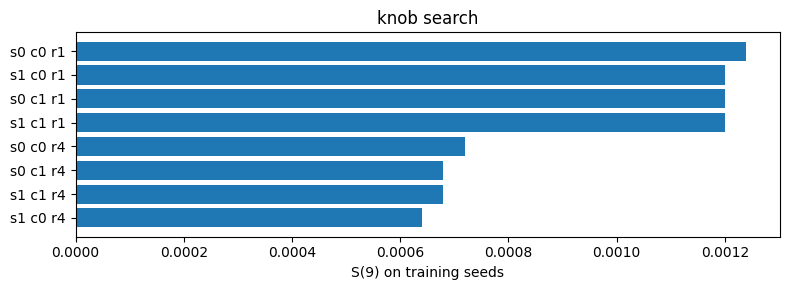

In [10]:
fig, ax = plt.subplots(figsize=(8, 3))
lab = board.apply(lambda r: f"s{r.w_scarce:g} c{r.w_close:g} r{r.rescue_from_round:g}", axis=1)
ax.barh(lab[::-1], board["S(9)"][::-1]); ax.set_xlabel("S(9) on training seeds"); ax.set_title("knob search")
plt.tight_layout()

## Step 6 · Validate on held-out seeds

Training picks the winner on the *same* seeds, so it may have been lucky. Here we re-run the top 2 configs and the
plain ceiling baseline on **100k fresh seeds each** and report P(record) with a 95% Wilson interval.

In [11]:
VALID_N = 100_000
cands = {"ceiling (baseline)": ("ceiling", {"target_sum": 995})}
for i in range(2):
    r = board.iloc[i]
    cands[f"hunter #{i + 1}"] = ("hunter", {k: (int(r[k]) if k == "rescue_from_round" else float(r[k])) for k in space})
valid, valid_dfs = [], {}
for label, (name, params) in cands.items():
    df = tr.evaluate(best_formation, name, params, range(VALID_START, VALID_START + VALID_N), WORKERS)
    valid_dfs[label] = df
    valid.append({"policy": label, "params": params, **tr.summarize(df)})
valid = pd.DataFrame(valid).sort_values("P(record)", ascending=False)
valid[["policy", "params", "games", "records", "P(record)", "ci_low", "ci_high", "S(9)", "ms_per_game_cpu"]]

,policy,params,games,records,P(record),ci_low,ci_high,S(9),ms_per_game_cpu
2,hunter #2,"{'w_scarce': 1.0, 'w_close': 0.0, 'w_ovr': 0.1...",100000,8,0.00008,0.000041,0.000158,0.00179,7.202270
0,ceiling (baseline),{'target_sum': 995},100000,7,0.00007,0.000034,0.000145,0.00177,7.913935
1,hunter #1,"{'w_scarce': 0.0, 'w_close': 0.0, 'w_ovr': 0.1...",100000,7,0.00007,0.000034,0.000145,0.00177,6.352240


In [12]:
winner = valid.iloc[0]
P = winner["P(record)"]
print(f"winner: {winner.policy} {winner.params} · P(record) = {P:.5f} (≈ 1 in {1 / P:,.0f}) "
      f"95% CI [{winner.ci_low:.5f}, {winner.ci_high:.5f}]")

winner: hunter #2 {'w_scarce': 1.0, 'w_close': 0.0, 'w_ovr': 0.1, 'rescue_from_round': 1} · P(record) = 0.00008 (≈ 1 in 12,500) 95% CI [0.00004, 0.00016]


**Honest takeaway:** swapping as soon as a game needs rescuing () clearly beats saving swaps
for later. The other knobs move survival a little, but the confidence intervals overlap. The record is driven by
the draws, and the policy's job is mainly not to waste them. Every config is far better than a human-style greedy game,
which never reached 995 in our earlier runs.

## Step 7 · Prove it: a record game, replayed

In [13]:
wdf = valid_dfs[winner.policy]
hit_seeds = wdf.loc[wdf.record, "seed"].tolist()
print(len(hit_seeds), "record seeds in validation, e.g.", hit_seeds[:5])
name, params = cands[winner.policy]
pol = st.POLICIES[name](pool, best_formation, **params)
g = sim.play(clubs, by_club, pol, best_formation, hit_seeds[0])
rep = engine.replay(clubs, by_club, "grandes", best_formation, g.seed, g.actions)   # what the site's server would check
assert rep and rep.lineup() == g.lineup()
print(f"sum {sum(p.ovr for p in g.xi.values())} → {g.average():.4f} → shown {g.average():.1f}; swaps used {2 - g.swaps}")
pd.DataFrame(g.lineup(), columns=["slot", "player", "club", "ovr"])

8 record seeds in validation, e.g. [5002613, 5012882, 5031074, 5062534, 5066765]
sum 995 → 90.4545 → shown 90.5; swaps used 2


,slot,player,club,ovr
0,PL1,Gyökeres,scp,94
1,PL2,Mário Jardel,scp,94
2,AE,Luis Díaz,fcp,90
3,MC1,Bruno Fernandes,scp,92
4,MC2,Deco,fcp,93
5,AD,Hulk,fcp,92
6,MDC,Matić,slb,88
7,DC1,Coates,scp,87
8,DC2,Ricardo Carvalho,fcp,90
9,DC3,Pepe,fcp,87


## Step 8 · Time plan

* **Offline:** CPU ms per game (from Step 2), divided by the worker count.
* **Live:** measured by the autopilot in a real browser, abandoning an attempt as soon as 995 is lost
  (latest `runs/live_*.csv`; about 0.4 s per attempt, ~3 picks each).

Attempts until the first record follow a geometric distribution: N = ln(1 − confidence) / ln(1 − p).

In [14]:
live_files = sorted(glob.glob(str(ROOT / "runs" / "live_*.csv")))
live = pd.concat([pd.read_csv(f) for f in live_files]) if live_files else pd.DataFrame()
live_hunt = live[live.get("status", pd.Series(dtype=str)).isin(["dead", "finished"])] if len(live) else live
secs_live = float(live_hunt.secs.mean()) if len(live_hunt) else 0.42
secs_offline = ms_abort / 1000 / WORKERS
print(f"per attempt → offline {secs_offline * 1000:.2f} ms (with {WORKERS} workers) · live {secs_live:.2f} s "
      f"(from {len(live_hunt)} measured live attempts)")
plan = tr.time_plan(P, 1.0)[["confidence", "attempts"]]
plan["offline"] = (plan.attempts * secs_offline).map(lambda s: f"{s:.1f} s")
plan["live autopilot"] = (plan.attempts * secs_live / 60).map(lambda m: f"{m:.0f} min")
plan["you + copilot (~8 s/attempt)"] = (plan.attempts * 8 / 3600).map(lambda h: f"{h:.1f} h")
plan

per attempt → offline 0.54 ms (with 7 workers) · live 0.46 s (from 12961 measured live attempts)


,confidence,attempts,offline,live autopilot,you + copilot (~8 s/attempt)
0,0.500,8664,4.7 s,67 min,19.3 h
1,0.632,12495,6.8 s,96 min,27.8 h
2,0.900,28781,15.6 s,221 min,64.0 h
3,0.990,57562,31.1 s,442 min,127.9 h


## Step 9 · Play live

**Autopilot** (`python -m onzeprime.live_bot hunt`): plays in headless Chromium, restarts in-page (no reloads) when 995
is lost, and stops with a screenshot when the record XI appears. Counter, ranking and analytics calls are blocked, so its
games never reach the public ranking.

**Copilot** (`python -m onzeprime.live_bot copilot --formation 3-5-2`): **you** play in a visible browser. A box at the
bottom shows the pick to make (outlined in green), when to tap *Trocar*, and when the attempt is dead so you can restart
right away. Nothing is blocked or clicked for you, so a record you make is a normal game.

In [15]:
RUN_LIVE = False          # set True to run a short autopilot hunt from here
if RUN_LIVE:
    from onzeprime.live_bot import LiveBot
    name, params = cands[winner.policy]
    with LiveBot(best_formation, name, params) as bot:
        stats = bot.hunt(max_attempts=300, max_minutes=5)
        print(stats, bot.save_log())

## Step 10 · Can any combination go higher than 995?

We recompute the exact ceiling for every formation under the current rules (v2), the old rules (v1: earlier positions
allowed, attacking MOs allowed at MC), and in Liga Completa (all 24 clubs).

In [16]:
from scipy.optimize import linear_sum_assignment
def ceiling(pl, f, rules):
    slots = engine.FORMATIONS[f]; ppl = sorted({p.id for p in pl}); col = {p: i for i, p in enumerate(ppl)}
    V = np.zeros((11, len(ppl)))
    for p in pl:
        for i, s in enumerate(slots):
            if engine.fits(p, s, rules): V[i, col[p.id]] = max(V[i, col[p.id]], p.ovr)
    r, c = linear_sum_assignment(-V); return int(V[r, c].sum())
liga = opt.pool_for_mode(by_club, "liga")
ceil = pd.DataFrame({f: {"Três Grandes (v2)": ceiling(pool, f, 2), "Três Grandes (v1)": ceiling(pool, f, 1),
                         "Liga Completa (v2)": ceiling(liga, f, 2)} for f in engine.FORMATIONS})
display(ceil)
print("max anywhere:", ceil.values.max(), "=", round(ceil.values.max() / 11, 4))

,4-4-2,4-3-3,4-2-3-1,4-2-4,3-4-3,3-5-2,5-3-2,5-4-1
Três Grandes (v2),995,989,990,995,991,995,988,988
Três Grandes (v1),995,989,990,995,991,995,988,988
Liga Completa (v2),995,989,990,995,991,995,988,988


max anywhere: 995 = 90.4545


**No.** 995 is the hard ceiling everywhere. Every 90+ player belongs to the Big Three, and the old rules add nothing at the
top. The "90,5" record can only be **tied**, never beaten, until the site adds players or changes ratings
(`data.fetch_bundle(force=True)` re-downloads the data, and Step 1 will show any new ceiling).

## Step 11 · Add your own bias

Every lever is a parameter of `RecordHunterPolicy`, so it also works live:
`python -m onzeprime.live_bot hunt --params '{"slot_bias": {"GR": 0.5}}' --headed`.

| Lever | Parameter | Idea to test |
|---|---|---|
| Role order | `slot_bias={"GR": 0.5}` / `{"DC": -0.3}` | Fill the keeper early, keep the flexible DC slots for last |
| Specific players | `player_bias={"Matić": 1}` | Lock a must-have the moment he appears |
| Club | `club_bias={"scp": 0.2}` | Prefer the club whose stars are scarcer |
| Proactive swap | `proactive_swap_below=0.6, proactive_until_round=2` | Redraw early when the only alive picks are "easy" ones |
| Rescue timing | `rescue_from_round` | Step 5b: 1 is best |
| Weights | `w_scarce`, `w_close`, `w_ovr` | Step 5b: small effect |

**Fair comparison:** every variant runs on the *same seeds* as the baseline (common random numbers), so a difference
comes from the bias and not from luck. Compare whole survival curves. Records are too rare to tell variants apart
under ~300k games each, but S(7) and S(9) move earlier.

In [17]:
BIAS_N = 60_000
BIAS_SEEDS = range(7_000_000, 7_000_000 + BIAS_N)
variants = {
    "baseline hunter":        {},
    "GR early":               {"slot_bias": {"GR": 0.5}},
    "DC last":                {"slot_bias": {"DC": -0.3}},
    "proactive swap (r≤2)":   {"proactive_swap_below": 0.6, "proactive_until_round": 2},
    # ← add your own, e.g. "lock Matić": {"player_bias": {"Matić": 1.0}},
}
bias_rows, bias_dfs = [], {}
for label, params in variants.items():
    df = tr.evaluate("3-5-2", "hunter", params, BIAS_SEEDS, WORKERS)
    bias_dfs[label] = df
    bias_rows.append({"variant": label, **tr.summarize(df)})
bias_tab = pd.DataFrame(bias_rows).set_index("variant")
base = bias_dfs["baseline hunter"]
bias_tab["ΔS(7) vs base"] = [(df.alive_picks >= 7).mean() - (base.alive_picks >= 7).mean() for df in bias_dfs.values()]
bias_tab[["games", "records", "P(record)", "S(4)", "S(7)", "S(9)", "ΔS(7) vs base", "mean_alive"]].round(5)

,games,records,P(record),S(4),S(7),S(9),ΔS(7) vs base,mean_alive
variant,,,,,,,,
baseline hunter,60000,13,0.00022,0.18508,0.01540,0.00192,0.00000,2.05655
GR early,60000,14,0.00023,0.18452,0.01538,0.00198,-0.00002,2.05500
DC last,60000,13,0.00022,0.18508,0.01540,0.00192,0.00000,2.05655
proactive swap (r≤2),60000,6,0.00010,0.04650,0.00288,0.00045,-0.01252,0.95738


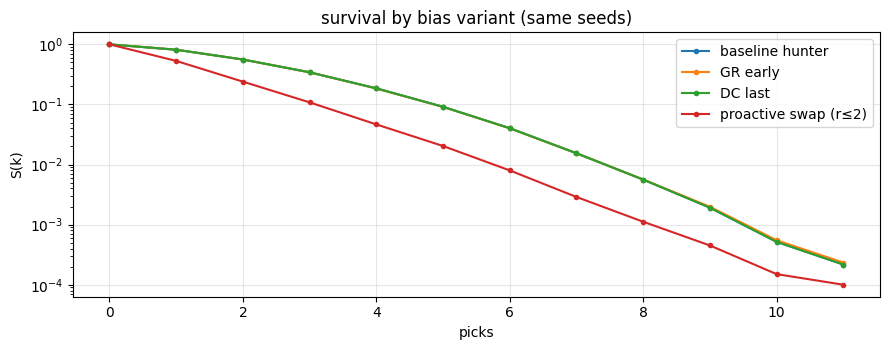

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for label, df in bias_dfs.items():
    s = tr.survival(df)
    ax.semilogy(s.index, s.values, marker="o", ms=3, label=label)
ax.set_xlabel("picks"); ax.set_ylabel("S(k)"); ax.set_title("survival by bias variant (same seeds)"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()

**Reading it:** a bias is worth keeping only if its curve sits above the baseline at k ≥ 7 *and* stays there on a second
set of seeds (re-run with another `BIAS_SEEDS` range). Then validate it as in Step 6 and pass it to the live bot with `--params`.